# HW 1 Part B: SIR model simulation

**Model** (S, I, R are numbers of people):
$$\frac{dS}{dt}=-\beta SI,\qquad \frac{dI}{dt}=\beta SI-\gamma I,\qquad \frac{dR}{dt}=\gamma I$$

**How the simulation works**
* `sir_rhs` (in `epimodels.py`) evaluates the right-hand side above: at any state $[S,I,R]$ it returns
  how fast each compartment changes per day.
* `simulate` starts from $[S(0),I(0),R(0)]$ and repeatedly applies one RK4 step of size $h$:
  each step samples the slope four times and moves the state forward by their weighted average.
  After $160/h = 1600$ steps it returns the time grid `t` and the trajectory `Y`.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from epimodels import sir_rhs, simulate

os.makedirs("figures", exist_ok=True) 

## Parameters (from the assignment; edit this cell for live changes)

In [ ]:
N      = 2000                            # total population (subjects/people)
y0     = np.array([1995.0, 5.0, 0.0])   # S(0), I(0), R(0) (people)
params = {"beta": 0.125e-3,             # transmission rate (per person per day)
          "gamma": 0.1}                 # recovery rate (per day)
t_end  = 160                            # duration (days)
h      = 0.1                            # RK4 step size (days), verified in Part A
method = "rk4"

## Run the simulation

In [3]:
t, Y = simulate(sir_rhs, y0, t_end, h, params, method=method)
S, I, R = Y.T                           # unpack columns into three time series

## checks

In [4]:
n_expected = int(round(t_end / h)) + 1

# 1. Array dimensions and time grid
assert t.shape == (n_expected,) and Y.shape == (n_expected, 3)
assert t[0] == 0 and np.isclose(t[-1], t_end) and np.allclose(np.diff(t), h)
print(f"t: {t.shape}, Y: {Y.shape}  (expected {n_expected} time points, t = 0 ... {t[-1]:g} days)")

# 2. Initial conditions are exactly the assignment's values
assert np.array_equal(Y[0], y0) and y0.sum() == N
print(f"Initial state: S = {S[0]:g}, I = {I[0]:g}, R = {R[0]:g}  (sum = {Y[0].sum():g} = N)")

# 3. Population conservation and nonnegativity
drift = np.abs(Y.sum(axis=1) - N).max()
assert drift / N < 1e-10 and Y.min() >= 0
print(f"max |S+I+R - N| = {drift:.2e} people; min compartment value = {Y.min():.3g}")
print("All checks passed.")

t: (1601,), Y: (1601, 3)  (expected 1601 time points, t = 0 ... 160 days)
Initial state: S = 1995, I = 5, R = 0  (sum = 2000 = N)
max |S+I+R - N| = 3.18e-12 people; min compartment value = 0
All checks passed.


## Plot S(t), I(t), R(t)

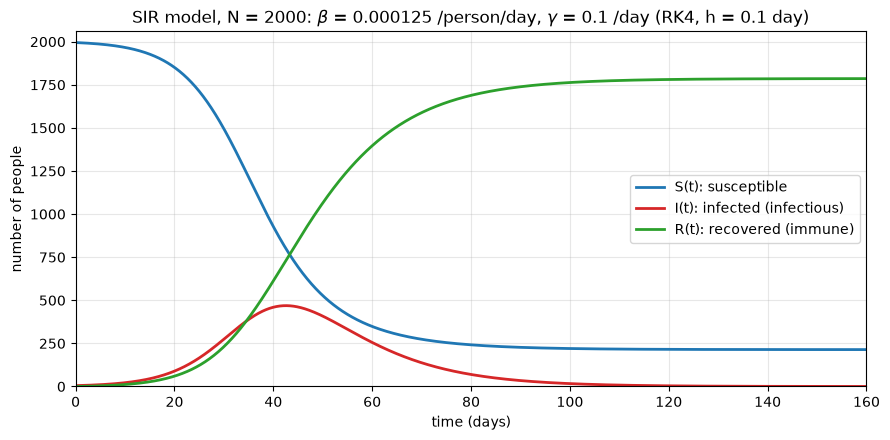

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t, S, color="tab:blue",  lw=2, label="S(t): susceptible")
ax.plot(t, I, color="tab:red",   lw=2, label="I(t): infected (infectious)")
ax.plot(t, R, color="tab:green", lw=2, label="R(t): recovered (immune)")
ax.set_xlim(0, t_end); ax.set_ylim(0, N * 1.03)
ax.set_xlabel("time (days)"); ax.set_ylabel("number of people")
ax.set_title(f"SIR model, N = {N}: "
             rf"$\beta$ = {params['beta']:.3g} /person/day, $\gamma$ = {params['gamma']} /day "
             f"(RK4, h = {h} day)")
ax.legend(loc="center right"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/partB_sir_simulation.png", dpi=150)
plt.show()